In [1]:
import sys
sys.path.insert(0, ".")
sys.path.insert(0, "../scripts")   # graficos/scripts/paleta.py

import numpy as np
import matplotlib.pyplot as plt
from paleta import CORES_ESTAGIO
from matplotlib.patches import Ellipse, Patch
from itertools import product
from dados_atividades import load_study_activities, load_study_stages, STAGE_NAMES, STAGE_ORDER

ELLIPSES = [
    dict(cx=0.35, cy=0.40, w=0.72, h=0.45, angle=140), 
    dict(cx=0.45, cy=0.50, w=0.72, h=0.45, angle=140), 
    dict(cx=0.55, cy=0.50, w=0.72, h=0.45, angle=40),  
    dict(cx=0.65, cy=0.40, w=0.72, h=0.45, angle=40),  
]

# cores dos estágios: 4 tons mais escuros da paleta compartilhada (graphic/paleta.py)
cores_estagio = CORES_ESTAGIO

In [2]:
def _ellipse_mask(x, y, cx, cy, w, h, angle):
    a = np.radians(angle)
    xr = (x - cx) * np.cos(a) + (y - cy) * np.sin(a)
    yr = -(x - cx) * np.sin(a) + (y - cy) * np.cos(a)
    return (xr / (w / 2)) ** 2 + (yr / (h / 2)) ** 2 <= 1


def compute_region_centroids(ellipses, grid=800):
    xs, ys = np.meshgrid(np.linspace(-0.1, 1.1, grid), np.linspace(-0.1, 1.1, grid))
    xs, ys = xs.ravel(), ys.ravel()
    masks = [_ellipse_mask(xs, ys, **e) for e in ellipses]
    centroids = {}
    for combo in product([0, 1], repeat=4):
        if combo == (0, 0, 0, 0):
            continue
        sel = np.ones_like(xs, dtype=bool)
        for bit, m in zip(combo, masks):
            sel &= m if bit else ~m
        if sel.sum() > 0:
            centroids[combo] = (xs[sel].mean(), ys[sel].mean())
    return centroids


centroids = compute_region_centroids(ELLIPSES)
print(f"Regiões não vazias na geometria: {len(centroids)}/15")

Regiões não vazias na geometria: 15/15


In [3]:
# estudos por combinação exata de estágios, contados em ../data/tabela_de_codigos.csv (dados_atividades.py)
from dados_atividades import REGIOES_VENN

region_counts = {}
for combo in product([0, 1], repeat=4):
    if combo == (0, 0, 0, 0):
        continue
    target = {STAGE_ORDER[i] for i, b in enumerate(combo) if b}
    region_counts[combo] = REGIOES_VENN[frozenset(target)]

assert sum(region_counts.values()) == sum(REGIOES_VENN.values())

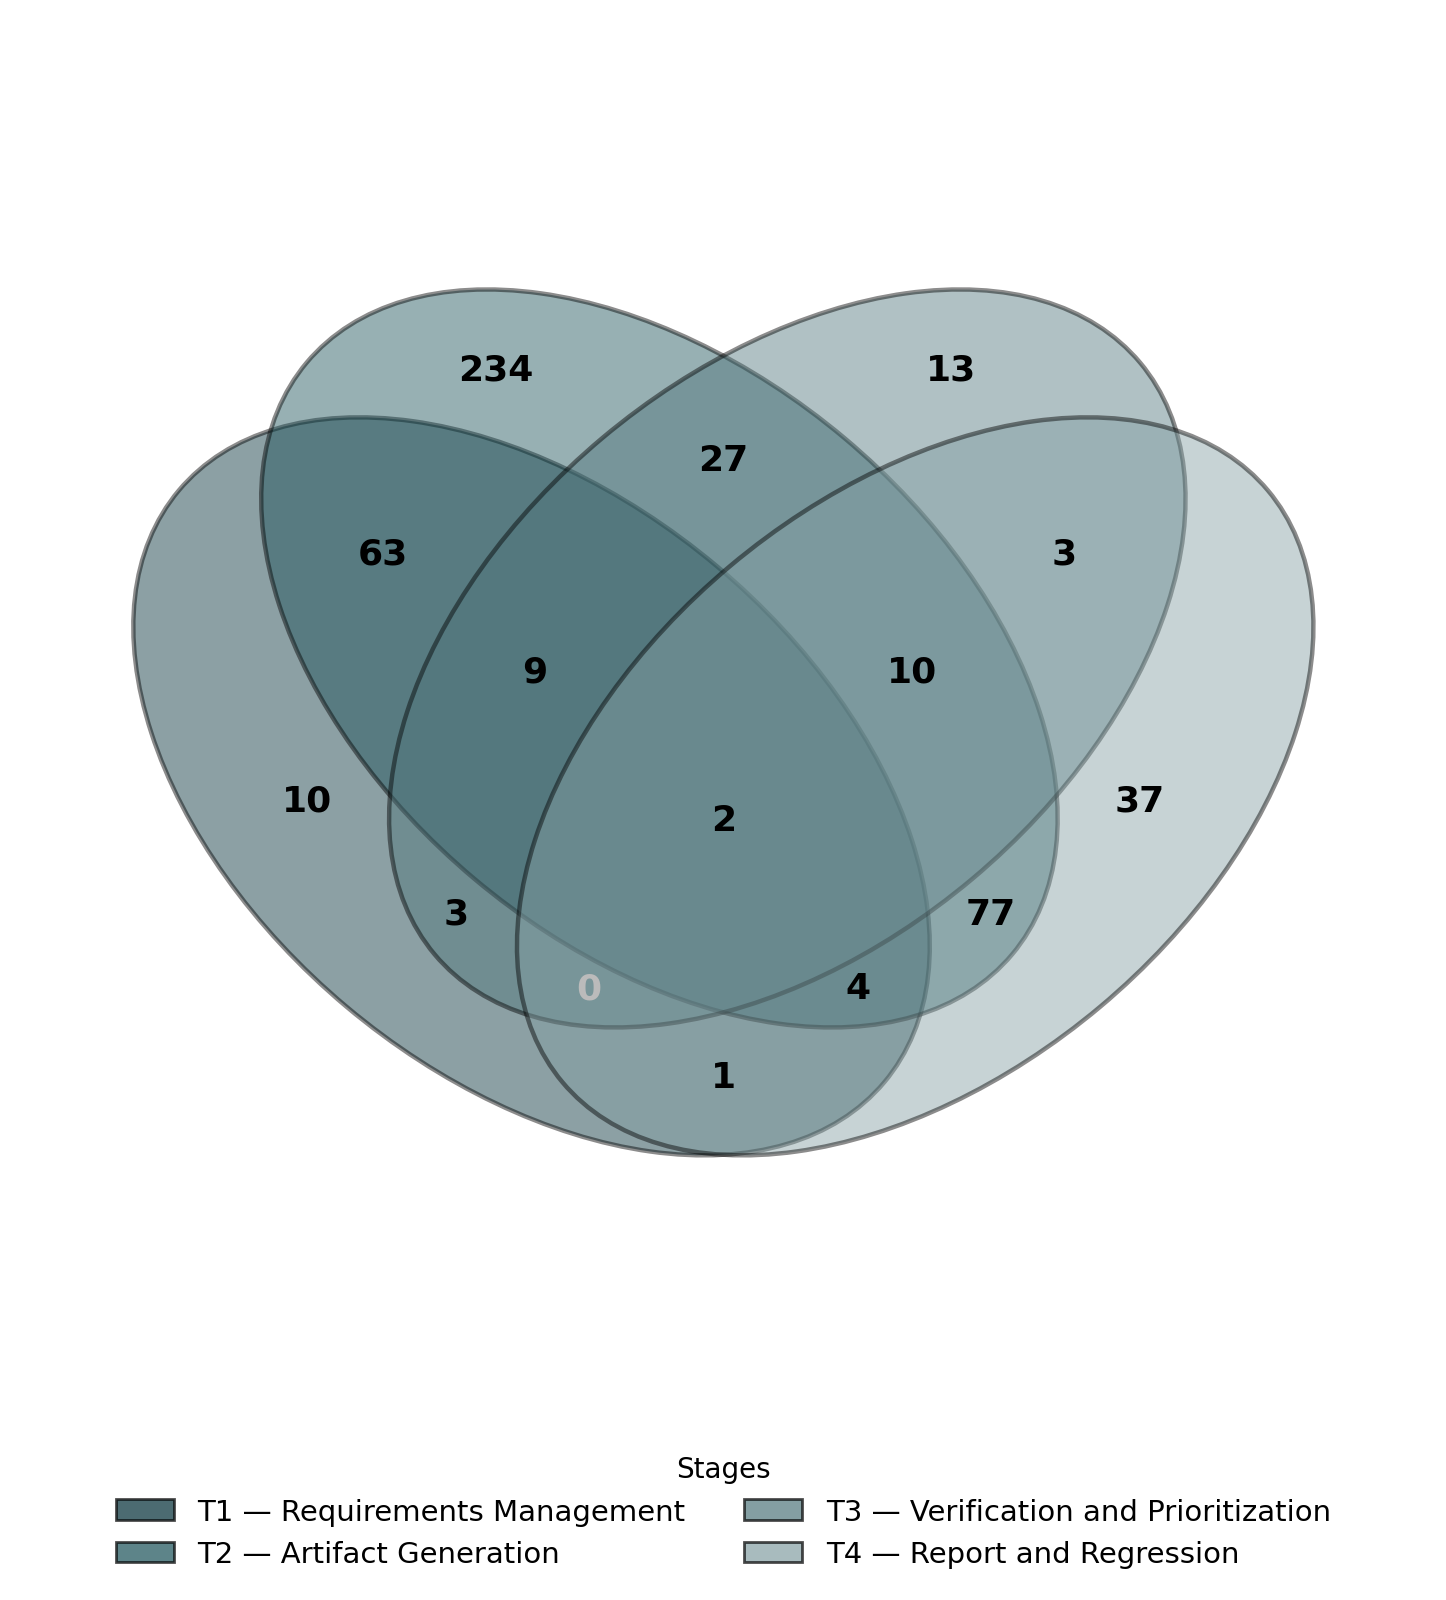

In [4]:
def desenhar_venn(cores, caminho_png, titulo_legenda):
    fig, ax = plt.subplots(figsize=(10, 8), dpi=200)

    for i, e in enumerate(ELLIPSES):
        stage = STAGE_ORDER[i]
        patch = Ellipse(
            (e["cx"], e["cy"]), e["w"], e["h"], angle=e["angle"],
            facecolor=cores[stage], edgecolor="black", linewidth=1.6,
            alpha=0.45, zorder=2,
        )
        ax.add_patch(patch)

    for combo, (cx, cy) in centroids.items():
        n = region_counts.get(combo, 0)
        cor_texto = "black" if n > 0 else "#bbbbbb"
        ax.text(cx, cy, str(n), ha="center", va="center", fontsize=13, fontweight="bold", color=cor_texto, zorder=5)

    legend_handles = [
        Patch(facecolor=cores[s], edgecolor="black", alpha=0.7, label=f"T{s} — {STAGE_NAMES[s]}")
        for s in STAGE_ORDER
    ]
    ax.legend(
        handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, -0.12),
        ncol=2, frameon=False, fontsize=10.5, title=titulo_legenda,
    )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.1, 1.0)
    ax.set_aspect("equal")
    ax.axis("off")

    plt.tight_layout()
    plt.savefig(caminho_png, bbox_inches="tight", dpi=200)
    plt.show()


desenhar_venn(cores_estagio, "venn_estagios_preto.png", "Stages")